In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,root_mean_squared_error

In [3]:
df=pd.read_csv("C:\\Users\\ADMIN\\OneDrive\\ドキュメント\\ML\\Session2\\Advertising.csv")

In [4]:
df

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9
...,...,...,...,...,...
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5


In [5]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [6]:
df

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [7]:
df.shape

(200, 4)

In [8]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [10]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
x=df[['TV', 'Radio', 'Newspaper']]
y=df['Sales']

In [13]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [14]:
mr=LinearRegression()

In [15]:
mr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
print(mr.coef_)
print(mr.intercept_)

[0.04472952 0.18919505 0.00276111]
2.979067338122631


In [17]:
Y_pred=mr.predict(x_test)

In [18]:
y_pred=mr.predict(x_train)

In [23]:
mse=mean_squared_error(Y_pred, y_test)
rmse=root_mean_squared_error(Y_pred, y_test)
mae=mean_absolute_error(Y_pred, y_test)
r2=r2_score(Y_pred, y_test)
print(mse)
print(rmse)
print(mae)
print(r2)


3.174097353976105
1.7815996615334504
1.4607567168117606
0.8791069137120033


In [24]:
residuals = y_test - Y_pred

<Axes: ylabel='Sales'>

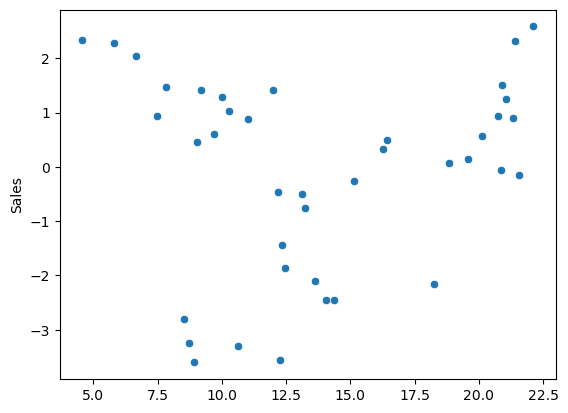

In [25]:
sns.scatterplot(x=Y_pred, y=residuals)

In [28]:
from warnings import filterwarnings
filterwarnings('ignore')

<Axes: xlabel='Sales', ylabel='Density'>

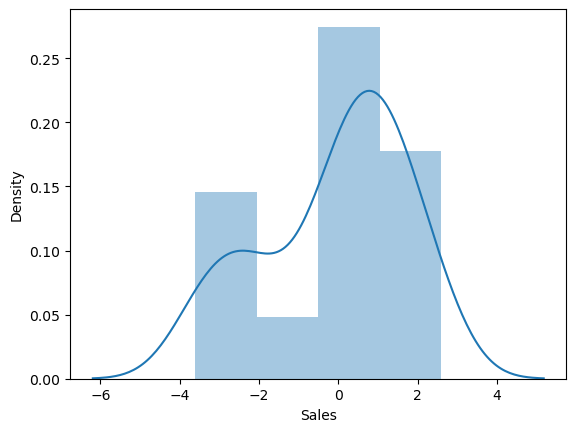

In [29]:
sns.distplot(residuals, kde=True)

In [ ]:
# Assuption of Linear Regression
# 1. Linearity = Relationship between independent and dependent variable is linear
# 2. Independence = errors are independent of each other
# 3. Homoscedasticity = errors variance should remain constant accross predicted values
# 4. Normality = errors should be normally distributed
# 5. No multicollinearity = independent variables should not be highly correlated with each other 
# 6. No outliers = there should be no extreme values in the data
# 7. No autocorrelation = errors should not be correlated with each other
# 8. No endogeneity = independent variables should not be correlated with the error term
# 9. No measurement error = independent variables should be measured without error